# Three hypotheses about what drives sales (Rebecca)

**Purpose.** This notebook checks three hypotheses about the bakery's turnover with descriptive statistics, visualizations and simple tests (week 3, step `1_DatasetCharacteristics`). It does not build a forecast model.

| | Hypothesis | Variables |
|---|---|---|
| **H1** | On weekends, turnover does **not** rise linearly with temperature; the relationship is an **inverted U** (turnover peaks at mild temperatures and falls again on hot days). | daily total turnover, mean daily temperature, Saturdays and Sundays |
| **H2** | More **bread** (group 1) is sold on **Mondays** than on other weekdays. | turnover of group 1, weekday |
| **H3** | Less **sweet bakery** is sold at the **end of the month**. | turnover of groups 3 (croissants), 4 (confectionery), 5 (cakes); last 5 days of a month |

**How to read the results.** The data covers 07/2013 – 07/2018. Turnover has no stated currency, so differences are given in turnover units and in percent. All intervals are 95 % confidence intervals of the *mean*: they say how precisely we know the average day, not how much a single day varies. p-values from daily time series are somewhat optimistic, because neighbouring days are not independent.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests
from pathlib import Path

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Colour-blind safe palette (Okabe-Ito)
GREY, BLUE, ORANGE, VERMILION = "#999999", "#0072B2", "#E69F00", "#D55E00"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.3, "axes.titleweight": "bold", "axes.titlesize": 11,
})
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
GROUPS = {1: "Bread", 2: "Rolls", 3: "Croissants", 4: "Confectionery", 5: "Cakes", 6: "Seasonal bread"}
TURNOVER = "turnover (currency not stated)"


def mean_ci(x, level=0.95):
    """Mean with a t-based confidence interval: returns n, mean, lower, upper."""
    x = pd.Series(x).dropna()
    n, m, se = len(x), x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    h = stats.t.ppf((1 + level) / 2, n - 1) * se
    return pd.Series({"n": n, "mean": m, "lower": m - h, "upper": m + h})


def err(tab):
    """Distances from the mean to the CI limits, as matplotlib expects them."""
    return [tab["mean"] - tab["lower"], tab["upper"] - tab["mean"]]

## 1. Load and merge the data

Sales, weather and Kiel Week are loaded from the course repository and joined on the date with a **left join**, so that every sales row stays. The checks below prove that the join did not add or lose rows.

In [2]:
sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
weather = pd.read_csv(BASE_URL + "wetter.csv", parse_dates=["Datum"])
kiel_week = pd.read_csv(BASE_URL + "kiwo.csv", parse_dates=["Datum"])

data = (sales.merge(weather, on="Datum", how="left", indicator="weather_match")
             .merge(kiel_week, on="Datum", how="left"))
data["KielerWoche"] = data["KielerWoche"].fillna(0).astype(int)

# Checks: the join keeps exactly one row per sales row
assert len(data) == len(sales) == 9334
assert not data.duplicated(["Datum", "Warengruppe"]).any()
no_weather = data.loc[data["weather_match"] == "left_only", "Datum"].dt.date.unique()
print("Rows before / after merge:", len(sales), "/", len(data))
print("Rows without weather:", (data["weather_match"] == "left_only").sum(), "on", sorted(no_weather))
print("Kiel Week days in the sales period:", data.loc[data["KielerWoche"] == 1, "Datum"].nunique())

Rows before / after merge: 9334 / 9334
Rows without weather: 16 on [datetime.date(2016, 12, 11), datetime.date(2017, 10, 4), datetime.date(2017, 10, 5)]
Kiel Week days in the sales period: 45


## 2. Dataset overview (from `/explore-data`)

A short profile of the three sources. The full fact sheet is in `docs/data-fact-sheet.md`.

In [3]:
calendar = pd.date_range(sales["Datum"].min(), sales["Datum"].max())
overview = pd.DataFrame({
    "rows": [len(sales), len(weather), len(kiel_week)],
    "first date": [d["Datum"].min().date() for d in (sales, weather, kiel_week)],
    "last date": [d["Datum"].max().date() for d in (sales, weather, kiel_week)],
    "one row is": ["one date and product group", "one date", "one Kiel Week day"],
}, index=["sales", "weather", "Kiel Week"])
display(overview)
print(f"Calendar days in the sales period: {len(calendar)}, days with sales: {sales['Datum'].nunique()}, "
      f"days without any sales: {len(calendar) - sales['Datum'].nunique()}")

per_group = sales.groupby("Warengruppe")["Umsatz"].describe()[["count", "mean", "50%", "std", "min", "max"]]
per_group.index = per_group.index.map(GROUPS)
display(per_group.round(1).rename(columns={"50%": "median"}))
print("Missing values in the weather file:")
display(weather.isna().sum().to_frame("missing").T)

,rows,first date,last date,one row is
sales,9334,2013-07-01,2018-07-31,one date and product group
weather,2601,2012-01-01,2019-08-01,one date
Kiel Week,72,2012-06-16,2019-06-30,one Kiel Week day


Calendar days in the sales period: 1857, days with sales: 1819, days without any sales: 38


,count,mean,median,std,min,max
Warengruppe,,,,,,
Bread,1819.0,122.1,120.1,40.3,23.1,416.8
Rolls,1819.0,402.5,370.8,139.7,175.0,1203.4
Croissants,1819.0,163.3,142.8,75.6,37.7,565.9
Confectionery,1766.0,88.0,80.0,35.3,27.4,430.5
Cakes,1819.0,276.8,266.0,99.5,121.5,1879.5
Seasonal bread,292.0,66.9,62.9,32.4,7.1,172.9


Missing values in the weather file:


,Datum,Bewoelkung,Temperatur,Windgeschwindigkeit,Wettercode
missing,0,10,0,0,669


**Daily table.** For H1 we need one row per day: the **daily total** is the sum of all product groups sold on that day. Days without any sales (mostly public holidays) are not in the data and are not filled in.

In [4]:
daily = (sales.groupby("Datum")["Umsatz"].sum().rename("total").to_frame()
              .join(weather.set_index("Datum"))
              .reset_index())
daily["total_groups_1_5"] = daily["Datum"].map(
    sales[sales["Warengruppe"] <= 5].groupby("Datum")["Umsatz"].sum())
daily["weekday"] = daily["Datum"].dt.dayofweek          # 0 = Monday
daily["year"] = daily["Datum"].dt.year
daily["weekend"] = daily["weekday"] >= 5
print(len(daily), "days;", daily["Temperatur"].isna().sum(), "without temperature")

1819 days; 3 without temperature


## 3. H1 – Weekend turnover and temperature: linear or inverted U?

**Approach.** Only Saturdays and Sundays with weather data. We compare two regression models for the daily total:

* linear: turnover = b0 + b1·T
* quadratic: turnover = b0 + b1·T + b2·T²

An **inverted U** needs (a) a **negative** b2 that is significantly different from 0, and (b) a turning point −b1 / (2·b2) **inside** the observed temperature range. The models are compared with an F-test and the AIC. As robustness checks, we add year and Saturday/Sunday as controls, and we repeat the analysis without seasonal bread (groups 1–5 only).

In [5]:
we = daily[daily["weekend"]].dropna(subset=["Temperatur"]).copy()
print(f"Weekend days: n = {len(we)}, temperature {we['Temperatur'].min():.1f} to {we['Temperatur'].max():.1f} °C")

bins = [-15, 0, 5, 10, 15, 20, 25, 35]
we["temp_band"] = pd.cut(we["Temperatur"], bins)
banded = we.groupby("temp_band", observed=True)["total"].apply(mean_ci).unstack()
banded["mean temperature"] = we.groupby("temp_band", observed=True)["Temperatur"].mean()
display(banded.round(1))

Weekend days: n = 520, temperature -8.5 to 28.8 °C


,n,mean,lower,upper,mean temperature
temp_band,,,,,
"(-15, 0]",21.0,1095.3,1001.7,1188.9,-2.0
"(0, 5]",75.0,1097.3,1034.4,1160.1,2.8
"(5, 10]",121.0,1148.6,1103.7,1193.4,7.5
"(10, 15]",82.0,1196.6,1149.7,1243.6,12.3
"(15, 20]",147.0,1361.4,1325.2,1397.6,17.4
"(20, 25]",60.0,1469.0,1409.5,1528.6,22.1
"(25, 35]",14.0,1524.3,1402.3,1646.2,26.0


In [6]:
rows = []
for y in ["total", "total_groups_1_5"]:
    lin_y = smf.ols(f"{y} ~ Temperatur", we).fit()
    quad_y = smf.ols(f"{y} ~ Temperatur + I(Temperatur**2)", we).fit()
    ctrl_y = smf.ols(f"{y} ~ Temperatur + I(Temperatur**2) + C(year) + C(weekday)", we).fit()
    f, p_f, _ = quad_y.compare_f_test(lin_y)
    rows.append({"outcome": y, "model": "linear", "b1 (T)": lin_y.params["Temperatur"],
                 "adj. R²": lin_y.rsquared_adj, "AIC": lin_y.aic})
    for name, m in [("quadratic", quad_y), ("quadratic + year + Sat/Sun", ctrl_y)]:
        b1, b2 = m.params["Temperatur"], m.params["I(Temperatur ** 2)"]
        rows.append({"outcome": y, "model": name, "b1 (T)": b1, "b2 (T²)": b2,
                     "p (b2)": m.pvalues["I(Temperatur ** 2)"], "turning point °C": -b1 / (2 * b2),
                     "adj. R²": m.rsquared_adj, "AIC": m.aic})
    print(f"{y}: F-test quadratic vs. linear: F = {f:.2f}, p = {p_f:.3f}")
h1_table = pd.DataFrame(rows)
display(h1_table.round(3))

lin = smf.ols("total ~ Temperatur", we).fit()
quad = smf.ols("total ~ Temperatur + I(Temperatur**2)", we).fit()

total: F-test quadratic vs. linear: F = 3.34, p = 0.068
total_groups_1_5: F-test quadratic vs. linear: F = 3.76, p = 0.053


,outcome,model,b1 (T),adj. R²,AIC,b2 (T²),p (b2),turning point °C
0,total,linear,18.383,0.241,7157.329,NaN,NaN,NaN
1,total,quadratic,10.555,0.245,7155.979,0.331,0.068,-15.920
2,total,quadratic + year + Sat/Sun,8.481,0.335,7095.578,0.374,0.033,-11.350
3,total_groups_1_5,linear,19.637,0.263,7166.632,NaN,NaN,NaN
4,total_groups_1_5,quadratic,11.257,0.267,7164.860,0.355,0.053,-15.861
5,total_groups_1_5,quadratic + year + Sat/Sun,9.606,0.346,7111.699,0.383,0.031,-12.530


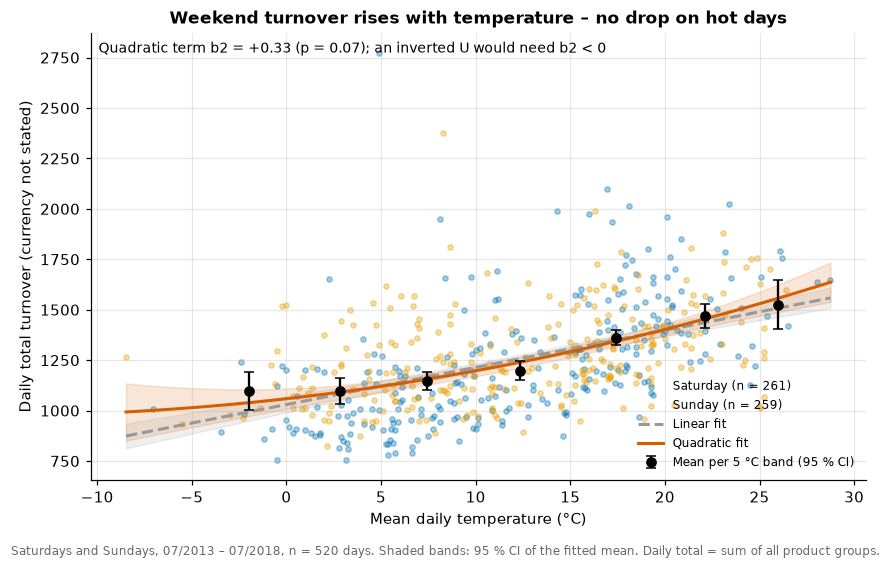

In [7]:
grid = pd.DataFrame({"Temperatur": np.linspace(we["Temperatur"].min(), we["Temperatur"].max(), 200)})
fig, ax = plt.subplots(figsize=(8, 5))
for wd, colour, label in [(5, BLUE, "Saturday"), (6, ORANGE, "Sunday")]:
    sub = we[we["weekday"] == wd]
    ax.scatter(sub["Temperatur"], sub["total"], s=12, alpha=0.35, color=colour, label=f"{label} (n = {len(sub)})")
for model, colour, style, label in [(lin, GREY, "--", "Linear fit"), (quad, VERMILION, "-", "Quadratic fit")]:
    pred = model.get_prediction(grid).summary_frame(alpha=0.05)
    ax.plot(grid["Temperatur"], pred["mean"], color=colour, ls=style, lw=2, label=label)
    ax.fill_between(grid["Temperatur"], pred["mean_ci_lower"], pred["mean_ci_upper"], color=colour, alpha=0.15)
ax.errorbar(banded["mean temperature"], banded["mean"], yerr=err(banded),
            fmt="o", color="black", ms=6, capsize=3, label="Mean per 5 °C band (95 % CI)")
b2, p_b2 = quad.params["I(Temperatur ** 2)"], quad.pvalues["I(Temperatur ** 2)"]
ax.set(xlabel="Mean daily temperature (°C)", ylabel=f"Daily total {TURNOVER}",
       title="Weekend turnover rises with temperature – no drop on hot days")
ax.text(0.01, 0.98, f"Quadratic term b2 = {b2:+.2f} (p = {p_b2:.2f}); an inverted U would need b2 < 0",
        transform=ax.transAxes, va="top", fontsize=9)
ax.legend(loc="lower right", fontsize=8, frameon=False)
fig.text(0.01, -0.02, f"Saturdays and Sundays, 07/2013 – 07/2018, n = {len(we)} days. "
         "Shaded bands: 95 % CI of the fitted mean. Daily total = sum of all product groups.",
         fontsize=8, color="dimgray")
fig.tight_layout()
fig.savefig(FIG_DIR / "rebecca_h1_weekend_temperature.png", bbox_inches="tight")
plt.show()

**Result H1 – not supported.**

* Weekend turnover rises steadily with temperature: from about 1,100 on days below 5 °C to about 1,500 on days above 20 °C (about +18 per °C in the linear model, adj. R² ≈ 0.24).
* The quadratic term is **positive**, not negative (b2 ≈ +0.33, p ≈ 0.07; with year and weekday controls p ≈ 0.03). The curve is therefore slightly **convex**: turnover rises a little faster on warm days. Its turning point (≈ −16 °C) lies outside the data, so there is no maximum within the observed range.
* The warmest band (above 25 °C, only 14 days) has the highest mean. There is no sign of a drop on hot days, although these days are few and their interval is wide.
* The result is the same without seasonal bread (groups 1–5).

**Caution.** Temperature goes together with summer: tourists, holidays and Kiel Week. The correlation with temperature therefore also contains a season effect. It is **not** a causal effect of temperature alone.

## 4. H2 – Is more bread sold on Mondays?

**Approach.** Turnover of group 1 (bread) per weekday with 95 % CI. Monday is compared with each other weekday using Welch's t-test (two groups with possibly different variances). Because these are six tests, the p-values are corrected with the **Holm** method. In addition, we look at bread's **share** of the daily total, which removes the effect of generally busier days.

In [8]:
bread = sales[sales["Warengruppe"] == 1].assign(weekday=lambda d: d["Datum"].dt.dayofweek)
bread_wd = bread.groupby("weekday")["Umsatz"].apply(mean_ci).unstack()
bread_wd.index = WEEKDAYS
display(bread_wd.round(1))

monday = bread.loc[bread["weekday"] == 0, "Umsatz"]
tests = []
for wd in range(1, 7):
    other = bread.loc[bread["weekday"] == wd, "Umsatz"]
    t = stats.ttest_ind(monday, other, equal_var=False)
    tests.append({"Monday vs.": WEEKDAYS[wd], "difference": monday.mean() - other.mean(),
                  "difference %": 100 * (monday.mean() / other.mean() - 1), "p (Welch)": t.pvalue})
tests = pd.DataFrame(tests)
tests["p (Holm)"] = multipletests(tests["p (Welch)"], method="holm")[1]
tests["significant at 5 %"] = tests["p (Holm)"] < 0.05
display(tests.round(4))

wide = sales.pivot(index="Datum", columns="Warengruppe", values="Umsatz")
share = (100 * wide[1] / wide.sum(axis=1)).rename("share").to_frame()
share["weekday"] = share.index.dayofweek
share_wd = share.groupby("weekday")["share"].apply(mean_ci).unstack()
share_wd.index = WEEKDAYS
display(share_wd.round(1))

,n,mean,lower,upper
Mon,258.0,133.1,129.0,137.3
Tue,262.0,118.5,115.1,121.8
Wed,263.0,116.7,112.9,120.5
Thu,259.0,135.6,130.8,140.5
Fri,256.0,127.8,123.8,131.8
Sat,261.0,147.9,142.3,153.5
Sun,260.0,75.6,72.6,78.6


,Monday vs.,difference,difference %,p (Welch),p (Holm),significant at 5 %
0,Tue,14.6799,12.3925,0.0000,0.0000,True
1,Wed,16.4575,14.1048,0.0000,0.0000,True
2,Thu,-2.5057,-1.8473,0.4389,0.4389,False
3,Fri,5.3308,4.1710,0.0668,0.1335,False
4,Sat,-14.7314,-9.9625,0.0000,0.0001,True
5,Sun,57.5190,76.0645,0.0000,0.0000,True


,n,mean,lower,upper
Mon,258.0,13.8,13.4,14.2
Tue,262.0,12.5,12.2,12.8
Wed,263.0,12.4,12.1,12.7
Thu,259.0,13.9,13.5,14.3
Fri,256.0,12.9,12.6,13.2
Sat,261.0,12.0,11.7,12.3
Sun,260.0,5.9,5.7,6.1


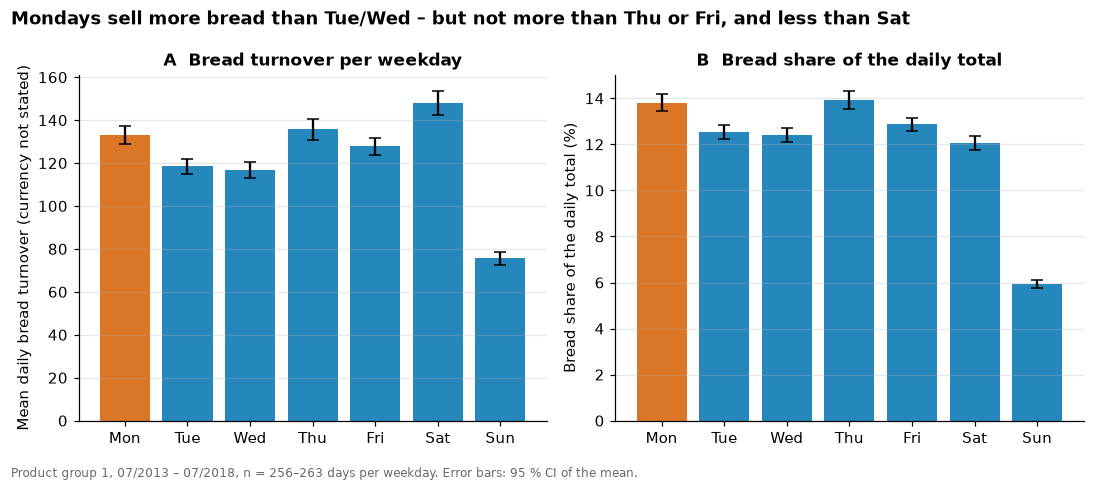

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
colours = [VERMILION if d == "Mon" else BLUE for d in WEEKDAYS]
for ax, tab, ylabel, title in [
    (axes[0], bread_wd, f"Mean daily bread {TURNOVER}", "A  Bread turnover per weekday"),
    (axes[1], share_wd, "Bread share of the daily total (%)", "B  Bread share of the daily total"),
]:
    ax.bar(WEEKDAYS, tab["mean"], color=colours, alpha=0.85)
    ax.errorbar(WEEKDAYS, tab["mean"], yerr=err(tab), fmt="none", ecolor="black", capsize=4)
    ax.set(ylabel=ylabel, title=title)
    ax.grid(axis="x", visible=False)
fig.suptitle("Mondays sell more bread than Tue/Wed – but not more than Thu or Fri, and less than Sat",
             fontweight="bold", x=0.01, ha="left")
fig.text(0.01, -0.03, f"Product group 1, 07/2013 – 07/2018, n = {bread_wd['n'].min():.0f}–{bread_wd['n'].max():.0f} "
         "days per weekday. Error bars: 95 % CI of the mean.", fontsize=8, color="dimgray")
fig.tight_layout()
fig.savefig(FIG_DIR / "rebecca_h2_bread_monday.png", bbox_inches="tight")
plt.show()

**Result H2 – partly supported.**

* On Mondays the bakery sells about **133** units of bread turnover, clearly more than on Tuesdays (≈ 119, +12 %), Wednesdays (≈ 117, +14 %) and Sundays (≈ 76). These differences remain significant after the Holm correction.
* Monday is **not** the peak: Thursday (≈ 136) is the same within the uncertainty, Friday (≈ 128) does not differ significantly after the correction, and **Saturday (≈ 148)** is clearly higher than Monday.
* Bread's share of the daily total shows the same pattern: Monday and Thursday ≈ 14 %, Sunday only ≈ 6 %.
* So the precise statement is: *Monday is one of the strong bread days, after Saturday and on a par with Thursday.* A possible explanation (not testable with this data) is restocking after Sunday, when little bread is sold.

## 5. H3 – Less sweet bakery at the end of the month?

**Definitions (open for discussion in the team).**

* *Sweet bakery* = product groups 3 (croissants), 4 (confectionery) and 5 (cakes), each analysed separately because their levels differ strongly.
* *End of month* = the **last 5 calendar days** of a month (e.g. 27 – 31 January, 24 – 28 February).

**Approach.** First a simple comparison of means (end of month vs. rest of the month). The end of December is special (Christmas, New Year's Eve), so everything is repeated **without December**. Then a regression with controls for weekday, month and year, so that, for example, a month end that happens to include more Saturdays does not distort the result. The three groups mean three tests, so the p-values are Holm-corrected.

In [10]:
sweet = sales[sales["Warengruppe"].isin([3, 4, 5])].copy()
sweet["days_to_month_end"] = sweet["Datum"].dt.days_in_month - sweet["Datum"].dt.day
sweet["month_end"] = sweet["days_to_month_end"] < 5
sweet["weekday"] = sweet["Datum"].dt.dayofweek
sweet["month"] = sweet["Datum"].dt.month
sweet["year"] = sweet["Datum"].dt.year

means, effects = [], []
for subset_name, subset in [("all months", sweet), ("without December", sweet[sweet["month"] != 12])]:
    for g in [3, 4, 5]:
        x = subset[subset["Warengruppe"] == g]
        for flag, label in [(False, "rest of month"), (True, "last 5 days")]:
            means.append({"months": subset_name, "group": GROUPS[g], "period": label,
                          **mean_ci(x.loc[x["month_end"] == flag, "Umsatz"])})
        m = smf.ols("Umsatz ~ month_end + C(weekday) + C(month) + C(year)", x).fit()
        lo, hi = m.conf_int().loc["month_end[T.True]"]
        base = x.loc[~x["month_end"], "Umsatz"].mean()
        b = m.params["month_end[T.True]"]
        effects.append({"months": subset_name, "group": GROUPS[g], "effect": b, "lower": lo, "upper": hi,
                        "effect %": 100 * b / base, "lower %": 100 * lo / base, "upper %": 100 * hi / base,
                        "p": m.pvalues["month_end[T.True]"]})
means, effects = pd.DataFrame(means), pd.DataFrame(effects)
effects["p (Holm)"] = effects.groupby("months")["p"].transform(lambda p: multipletests(p, method="holm")[1])
display(means.round(1))
display(effects.round(3))

,months,group,period,n,mean,lower,upper
0,all months,Croissants,rest of month,1517.0,162.5,158.7,166.3
1,all months,Croissants,last 5 days,302.0,167.7,159.1,176.2
2,all months,Confectionery,rest of month,1482.0,88.4,86.5,90.2
3,all months,Confectionery,last 5 days,284.0,85.8,82.3,89.3
4,all months,Cakes,rest of month,1517.0,272.2,268.9,275.5
5,all months,Cakes,last 5 days,302.0,299.7,277.8,321.6
6,without December,Croissants,rest of month,1398.0,167.5,163.5,171.5
7,without December,Croissants,last 5 days,278.0,168.0,158.7,177.2
8,without December,Confectionery,rest of month,1372.0,89.1,87.2,91.1
9,without December,Confectionery,last 5 days,267.0,85.8,82.2,89.3


,months,group,effect,lower,upper,effect %,lower %,upper %,p,p (Holm)
0,all months,Croissants,5.701,0.757,10.644,3.509,0.466,6.551,0.024,0.048
1,all months,Confectionery,-3.356,-6.804,0.093,-3.797,-7.700,0.106,0.057,0.057
2,all months,Cakes,27.397,16.198,38.596,10.064,5.950,14.177,0.000,0.000
3,without December,Croissants,0.946,-4.268,6.161,0.565,-2.548,3.678,0.722,0.722
4,without December,Confectionery,-3.703,-7.302,-0.103,-4.155,-8.195,-0.116,0.044,0.131
5,without December,Cakes,-3.312,-9.517,2.893,-1.193,-3.427,1.042,0.295,0.590


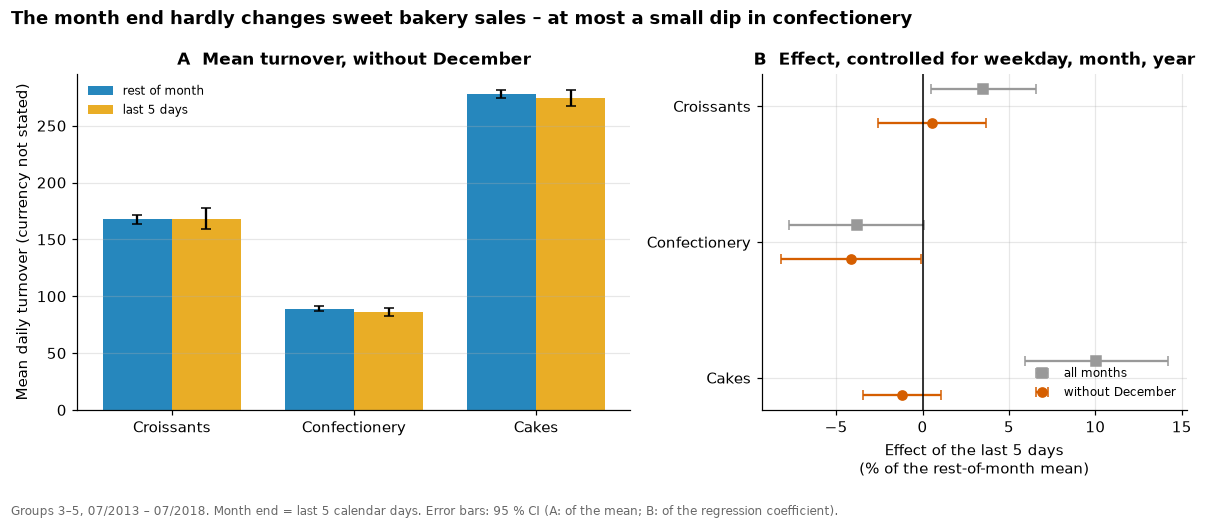

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
order = [GROUPS[g] for g in [3, 4, 5]]

# A: means without December
ax = axes[0]
m = means[means["months"] == "without December"]
x = np.arange(3)
for i, (label, colour) in enumerate([("rest of month", BLUE), ("last 5 days", ORANGE)]):
    sub = m[m["period"] == label].set_index("group").loc[order]
    pos = x + (i - 0.5) * 0.38
    ax.bar(pos, sub["mean"], width=0.38, color=colour, alpha=0.85, label=label)
    ax.errorbar(pos, sub["mean"], yerr=err(sub), fmt="none", ecolor="black", capsize=3)
ax.set_xticks(x, order)
ax.set(ylabel=f"Mean daily {TURNOVER}", title="A  Mean turnover, without December")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)

# B: effect of the month end, controlled for weekday, month and year
ax = axes[1]
for j, (subset_name, colour, marker) in enumerate([("all months", GREY, "s"), ("without December", VERMILION, "o")]):
    e = effects[effects["months"] == subset_name].set_index("group").loc[order]
    y = np.arange(3) + (j - 0.5) * 0.25
    ax.errorbar(e["effect %"], y, xerr=[e["effect %"] - e["lower %"], e["upper %"] - e["effect %"]],
                fmt=marker, color=colour, capsize=3, label=subset_name)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(np.arange(3), order)
ax.invert_yaxis()
ax.set(xlabel="Effect of the last 5 days\n(% of the rest-of-month mean)",
       title="B  Effect, controlled for weekday, month, year")
ax.legend(frameon=False, fontsize=8, loc="lower right")

fig.suptitle("The month end hardly changes sweet bakery sales – at most a small dip in confectionery",
             fontweight="bold", x=0.01, ha="left")
fig.text(0.01, -0.04, "Groups 3–5, 07/2013 – 07/2018. Month end = last 5 calendar days. "
         "Error bars: 95 % CI (A: of the mean; B: of the regression coefficient).", fontsize=8, color="dimgray")
fig.tight_layout()
fig.savefig(FIG_DIR / "rebecca_h3_sweet_month_end.png", bbox_inches="tight")
plt.show()

**Result H3 – largely not supported.**

* **Croissants:** without December there is no month-end effect (about 168 in both periods). Across all months the controlled model shows slightly *more* croissants at the month end (≈ +3.5 %), which again comes from the end of December – the opposite of the hypothesis.
* **Cakes:** across all months, cakes sell *more* at the month end, but this comes entirely from December (Christmas and New Year's Eve). Without December there is no effect.
* **Confectionery:** a small dip of about 3 – 4 turnover units (≈ 4 %) at the month end. It is borderline: without December p ≈ 0.04 in the controlled model, and not significant after the Holm correction across three groups.
* So the data does not show that less sweet bakery is sold at the end of the month. If there is an effect, it is small and limited to confectionery; for the forecast, weekday and season matter far more.

## 6. Summary

| | Hypothesis | Verdict | Key number |
|---|---|---|---|
| H1 | Inverted U between temperature and weekend turnover | **not supported**: rises with temperature, slightly convex | ≈ 1,100 below 5 °C vs. ≈ 1,500 above 20 °C |
| H2 | More bread on Mondays | **partly supported**: more than Tue/Wed/Sun, not more than Thu/Fri, less than Sat | Mon ≈ 133 vs. Tue ≈ 119 (+12 %), Sat ≈ 148 |
| H3 | Less sweet bakery at the month end | **largely not supported**: at most a small dip in confectionery | confectionery ≈ −4 %, not significant after correction |

**What the data cannot tell.** Turnover is what was sold, not what customers wanted (sold-out days hide demand). Temperature stands in for summer as a whole, so H1 does not show a causal effect of temperature. The weather is the observed weather, not the forecast that the operations manager would know the day before.

**For feature engineering (week 4):** temperature will probably work as a roughly linear feature (together with month or season); weekday stays the strongest calendar feature; a month-end flag is unlikely to help.